# Hồi quy và baseline dự báo tổng khách tháng tiếp theo

26 mẫu tháng 07/2015–08/2017, 5 phương pháp, mỗi origin dự báo đúng một tháng tới.

Bản viết lại từ `monthly_demand_forecast.ipynb`, bản cũ được giữ nguyên.
Chọn kernel `.venv`, chạy từ trên xuống (Restart Kernel → Run All).
Nguồn mặc định là snapshot cố định đã lưu, không cần PostgreSQL hoặc `docs/ml` cũ.
Quality PASS là evidence của snapshot, không phải kiểm tra DB mới.
Target là khách của booking cuối cùng không hủy theo ngày đến, không phải occupancy/check-in thực.
Holdout 06–08/2017 đã được xem ở thí nghiệm trước, kết quả là hồi cứu, mang tính khám phá.

## 1. Thiết lập

Chỉ dùng các thư viện đã có trong `ml/requirements.txt`. Mỗi lần chạy tạo
thư mục artifact riêng, không sửa dữ liệu nguồn hoặc kết quả cũ.

In [1]:
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pipeline/config/dw_operations.json').is_file())
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

In [2]:
SOURCE_DIR = ROOT / 'artifacts/forecasting/history_demand_causal_methods/20261109T110426_146bf398'
NOTEBOOK_PATH = ROOT / 'notebooks/experiments/monthly_demand_forecast_report.ipynb'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid4().hex[:8]
OUT = ROOT / 'artifacts/forecasting/monthly_demand_forecast_report' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
DAY = pd.Timedelta(days=1)
TRAIN_START, TEST_END = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
SEED = 42
print('Artifacts:', OUT.relative_to(ROOT))

Artifacts: artifacts\forecasting\monthly_demand_forecast_report\20261110T051147_8eba5ce2


In [3]:
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(name, value):
    with (OUT / name).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, ensure_ascii=False, indent=2, default=str, allow_nan=False)
def save_csv(name, frame):
    frame.to_csv(OUT / name, index=False, float_format='%.12g')
save_json('environment.json', {'python': platform.python_version(), **{
    name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'scikit-learn')}})

## 2. Load data và kiểm tra nguồn

Kiểm tra checksum trước khi đọc. Daily và booking phải thuộc cùng published snapshot,
khóa booking là checksum nguồn + row ordinal. Không gộp dòng vì giống thuộc tính.

In [4]:
inventory = json.loads((SOURCE_DIR / 'input_manifest.json').read_text(encoding='utf-8'))
for name in ('daily_input.csv', 'booking_input.csv', 'provenance.json', 'quality.json'):
    assert sha(SOURCE_DIR / name) == inventory[name], f'Input changed: {name}'
provenance = json.loads((SOURCE_DIR / 'provenance.json').read_text(encoding='utf-8'))
quality = json.loads((SOURCE_DIR / 'quality.json').read_text(encoding='utf-8'))
assert all(q['passed'] and not q['errors'] for q in quality.values())
assert all(q['data_version'] == provenance['data_version'] for q in quality.values())
daily = pd.read_csv(SOURCE_DIR / 'daily_input.csv', parse_dates=['full_date'])
bookings = pd.read_csv(SOURCE_DIR / 'booking_input.csv', parse_dates=['full_date'])
print('Data version:', provenance['data_version'])
pd.DataFrame({'dataset': ['daily', 'booking'], 'rows': [len(daily), len(bookings)]})

Data version: 323b1759-994c-4c66-8ca3-8d73e5a11acb


,dataset,rows
0,daily,793
1,booking,79250


In [5]:
daily_ints = ['date_key', 'observed_total_guests', 'target_guests', 'non_canceled_bookings',
              'guest_valid_booking_count', 'missing_guest_bookings_count',
              'guest_ineligible_booking_count', 'rejected_booking_count', 'excluded_booking_count']
for frame, names in ((daily, daily_ints), (bookings, ['source_row_id', 'is_canceled', 'total_guests'])):
    for name in names:
        values = pd.to_numeric(frame[name], errors='raise')
        frame[name] = values.astype('Int64')
assert pd.DatetimeIndex(daily.full_date).equals(pd.date_range(TRAIN_START, TEST_END))
assert set(daily.data_version) == {provenance['data_version']}
assert daily.guest_data_status.eq('COMPLETE').equals(daily.target_guests.notna())
assert set(bookings.source_file_sha256) == {provenance['source_checksums']['booking']}

In [6]:
valid = bookings[(bookings.is_canceled == 0) & bookings.guest_eligible].copy()
observed = valid.groupby('full_date').total_guests.agg(['sum', 'count'])
observed = observed.reindex(daily.full_date, fill_value=0)
np.testing.assert_array_equal(observed['sum'], daily.observed_total_guests)
np.testing.assert_array_equal(observed['count'], daily.guest_valid_booking_count)
source_hashes = {name: sha(SOURCE_DIR / name) for name in inventory}
old_paths = [p for p in (ROOT / 'notebooks').rglob('*.ipynb') if not p.stem.endswith('_report')]
old_hashes = {str(p.relative_to(ROOT)): sha(p) for p in old_paths}
save_json('source.json', {'snapshot': str(SOURCE_DIR.relative_to(ROOT)), 'provenance': provenance,
                          'input_checksums': source_hashes, 'point_in_time_verified': False})

### Bổ sung loại phòng đặt

Snapshot booking chưa có loại phòng. Đọc `reserved_room_type` từ đúng raw đã ghim
checksum, ghép bằng row ordinal, chỉ giữ booking đã có trong snapshot.
Đây là thuộc tính phục vụ bù nhãn, không phải feature tương lai đưa vào model.

In [7]:
source_set = json.loads((ROOT / 'docs/data_dictionary/operations_source_set.json').read_text(encoding='utf-8'))
room_source = source_set['sources']['booking']
room_path = ROOT / room_source['file']
assert sha(room_path) == room_source['sha256'] == provenance['source_checksums']['booking']
room_rows = pd.read_csv(room_path, usecols=['reserved_room_type'], keep_default_na=False)
room_rows['source_row_id'] = np.arange(2, len(room_rows) + 2)
bookings = bookings.merge(room_rows, on='source_row_id', how='left', validate='one_to_one', indicator=True)
assert bookings._merge.eq('both').all(), 'Room source does not cover the snapshot'
bookings = bookings.drop(columns='_merge')
bookings['reserved_room_type'] = bookings.reserved_room_type.astype('string').str.strip().replace('', pd.NA)
valid = bookings[bookings.is_canceled.eq(0) & bookings.guest_eligible].copy()
save_json('room_source.json', {'file': room_source['file'], 'sha256': sha(room_path),
                             'join_key': 'source checksum + source_row_id', 'rows': len(bookings)})
bookings[['source_row_id', 'full_date', 'reserved_room_type', 'total_guests', 'guest_eligible']].head()

,source_row_id,full_date,reserved_room_type,total_guests,guest_eligible
0,40062,2015-07-01,A,1,True
1,40063,2015-07-01,A,2,True
2,40064,2015-07-01,A,1,True
3,40065,2015-07-01,A,2,True
4,74968,2015-07-01,A,2,True


## 3. Chia train, validation và test

12 tháng đầu làm train ban đầu. Validation là 11 one-step origin 07/2016–05/2017,
test rolling 06–08/2017. Mỗi origin refit bằng các tháng trước đó, sau khi đã chốt.
Không dự báo đồng thời cả ba tháng test từ 31/05. Timestamp chốt thực tế chưa xác minh.

In [8]:
MODELS = ('M0_last_month_rate', 'M1_seasonal_naive12', 'M2_OLS_trend',
          'M3_seasonal_Ridge', 'M4_seasonal_blend')
validation_months = pd.period_range('2016-07', '2017-05', freq='M')
test_months = pd.period_range('2017-06', '2017-08', freq='M')
pd.DataFrame({'partition': ['initial train', 'validation', 'test'],
    'start': ['2015-07', '2016-07', '2017-06'], 'end': ['2016-06', '2017-05', '2017-08'],
    'months': [12, len(validation_months), len(test_months)]})

,partition,start,end,months
0,initial train,2015-07,2016-06,12
1,validation,2016-07,2017-05,11
2,test,2017-06,2017-08,3


## 4. Tiền xử lý và tổng hợp tháng

Mean theo loại phòng chỉ học từ booking train trước mỗi origin. Giữ subtotal quan sát, cộng phần
booking ZERO_GUESTS thiếu đủ điều kiện. Mỗi tháng phải đủ ngày, không cộng NULL rồi mất ngày.
Target tháng = observed + phần bù, báo số ngày và tháng có nhãn ước tính.

### Mean theo loại phòng trong train

Tính số khách/booking hợp lệ, không hủy, theo `reserved_room_type`.
Nhóm có ít nhất **30 booking** dùng mean riêng, nhóm ít mẫu/không biết/chưa gặp
dùng mean chung train. Ngưỡng 30 cố định, không chọn bằng điểm test.
Bù từng booking ZERO_GUESTS đủ điều kiện rồi cộng với subtotal quan sát của ngày.
Giữ nguyên ngày COMPLETE và zero hợp lệ. Nhãn sau bù vẫn là ước tính.

In [9]:
MIN_ROOM_BOOKINGS = 30
IMPUTATION_POLICY = {'method': 'room_type_mean', 'group_column': 'reserved_room_type',
                     'min_room_bookings': MIN_ROOM_BOOKINGS, 'fallback': 'train_global_mean'}
def fit_room_imputer(cutoff):
    train = valid[valid.full_date.between(TRAIN_START, pd.Timestamp(cutoff))]
    mu = float(train.total_guests.mean())
    rooms = train.groupby('reserved_room_type').total_guests.agg(['count', 'sum', 'mean'])
    rooms['use_room_mean'] = rooms['count'].ge(MIN_ROOM_BOOKINGS)
    rooms['fill_mean'] = rooms['mean'].where(rooms.use_room_mean, mu)
    return {**IMPUTATION_POLICY, 'mu_train': mu, 'fit_start': str(TRAIN_START.date()),
            'fit_end': str(pd.Timestamp(cutoff).date()), 'fit_label_cutoff': str(pd.Timestamp(cutoff).date()),
            'known_guest_sum': int(train.total_guests.sum()), 'known_booking_count': len(train),
            'rooms': rooms.to_dict(orient='index')}

In [10]:
def room_mean_table(imputer):
    return pd.DataFrame.from_dict(imputer['rooms'], orient='index').rename_axis('reserved_room_type').reset_index()
def room_estimates(imputer, end):
    mask = bookings.is_canceled.eq(0) & ~bookings.guest_eligible & bookings.full_date.le(pd.Timestamp(end))
    missing = bookings.loc[mask].copy()
    means = {room: stats['fill_mean'] for room, stats in imputer['rooms'].items()}
    used = {room: stats['use_room_mean'] for room, stats in imputer['rooms'].items()}
    missing['estimated_guests'] = missing.reserved_room_type.map(means).astype(float).fillna(imputer['mu_train'])
    missing['imputation_source'] = np.where(missing.reserved_room_type.map(used).eq(True), 'ROOM_MEAN', 'GLOBAL_MEAN')
    return missing
def save_room_imputation(prefix, imputer, end):
    save_json(prefix + '_imputer.json', imputer)
    save_csv(prefix + '_room_means.csv', room_mean_table(imputer))
    save_csv(prefix + '_imputed_bookings.csv', room_estimates(imputer, end))

In [11]:
def eligible_imputation(frame):
    return (frame.guest_data_status.eq('PARTIAL') & frame.booking_data_status.eq('COMPLETE')
            & frame.rejected_booking_count.eq(frame.excluded_booking_count)
            & frame.missing_guest_bookings_count.gt(0)
            & frame.guest_ineligible_booking_count.eq(frame.missing_guest_bookings_count)
            & frame.non_canceled_bookings.eq(frame.guest_valid_booking_count + frame.missing_guest_bookings_count))

In [12]:
def room_labels(cutoff, end):
    frame = daily[daily.full_date.le(pd.Timestamp(end))].copy()
    imputer = fit_room_imputer(cutoff)
    additions = room_estimates(imputer, end).groupby('full_date').estimated_guests.sum()
    frame['target_true'] = frame.target_guests.astype(float)
    frame['estimated_missing_guests'] = frame.full_date.map(additions).fillna(0.)
    mask = eligible_imputation(frame)
    frame.loc[~mask, 'estimated_missing_guests'] = 0.
    frame['target_estimated'] = frame.target_true.copy()
    frame.loc[mask, 'target_estimated'] = (frame.loc[mask, 'observed_total_guests'].astype(float)
                                         + frame.loc[mask, 'estimated_missing_guests'])
    frame['target_is_imputed'] = mask.to_numpy(dtype=bool)
    frame['partition'] = np.where(frame.full_date.le(pd.Timestamp(cutoff)), 'train', 'evaluation')
    return frame, imputer

In [13]:
preview_imputer = fit_room_imputer(pd.Timestamp('2016-06-30'))
print('Mean chung train:', round(preview_imputer['mu_train'], 6), ', tối thiểu', MIN_ROOM_BOOKINGS, 'booking/loại phòng')
room_mean_table(preview_imputer).round(4)

Mean chung train: 1.849305 , tối thiểu 30 booking/loại phòng


,reserved_room_type,count,sum,mean,use_room_mean,fill_mean
0,A,14986,26325,1.7566,True,1.7566
1,B,395,824,2.0861,True,2.0861
2,C,4,7,1.7500,False,1.8493
3,D,2405,5050,2.0998,True,2.0998
4,E,202,401,1.9851,True,1.9851
5,F,344,1235,3.5901,True,3.5901
6,G,72,200,2.7778,True,2.7778


In [14]:
def monthly_labels(cutoff, end):
    frame, imputer = room_labels(cutoff, end)
    assert frame.target_estimated.notna().all(), 'Unresolved day: do not silently sum a partial month'
    frame['month'] = frame.full_date.dt.to_period('M')
    monthly = frame.groupby('month', sort=True).agg(
        target=('target_estimated', 'sum'), observed=('observed_total_guests', 'sum'),
        estimated_addition=('estimated_missing_guests', 'sum'), calendar_days=('full_date', 'size'),
        imputed_days=('target_is_imputed', 'sum'), missing_bookings=('missing_guest_bookings_count', 'sum'))
    monthly['rate'] = monthly.target / monthly.calendar_days
    monthly['target_is_estimated'] = monthly.imputed_days.gt(0)
    return monthly, imputer

## 5. Kiến trúc và cấu hình

M0: rate guest/day tháng trước × số ngày tháng đích.
M1: nguyên tổng cùng tháng năm trước. M2: OLS tổng khách theo month_index.
M3: StandardScaler + Ridge alpha=10, trend và sin/cos năm, học guest/day rồi đổi về tổng.
M4: blend 50/50 rate tháng trước và rate cùng tháng năm trước. Không grid search.

In [15]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [16]:
def calendar_features(months, seasonal=False):
    months = pd.PeriodIndex(months, freq='M')
    result = pd.DataFrame({'month_index': [p.ordinal - pd.Period('2015-07', freq='M').ordinal for p in months]})
    if seasonal:
        phase = 2 * np.pi * (months.month - 1) / 12
        result['year_sin'], result['year_cos'] = np.sin(phase), np.cos(phase)
    return result

In [17]:
def predict_month(name, train, target):
    assert target == train.index[-1] + 1 and len(train) >= 12
    if name == 'M0_last_month_rate':
        return float(train.rate.iloc[-1] * target.days_in_month)
    if name == 'M1_seasonal_naive12':
        return float(train.at[target - 12, 'target'])
    if name == 'M4_seasonal_blend':
        return float(.5 * (train.rate.iloc[-1] + train.at[target - 12, 'rate']) * target.days_in_month)
    if name == 'M2_OLS_trend':
        model = LinearRegression().fit(calendar_features(train.index), train.target)
        return float(model.predict(calendar_features([target]))[0])
    model = make_pipeline(StandardScaler(), Ridge(alpha=10.))
    model.fit(calendar_features(train.index, seasonal=True), train.rate)
    return float(model.predict(calendar_features([target], seasonal=True))[0] * target.days_in_month)

### In feature theo từng mô hình

OLS chỉ có month_index, seasonal Ridge có thêm year_sin/year_cos.
In tên và mẫu giá trị trên 12 tháng train ban đầu. Các baseline dùng lịch sử
tổng/rate khách, khác ma trận feature hồi quy, số ngày tháng đích dùng để đổi rate về tổng.

In [18]:
preview_months = pd.period_range('2015-07', '2016-06', freq='M')
feature_inputs = {'M2_OLS_trend': calendar_features(preview_months),
                  'M3_seasonal_Ridge': calendar_features(preview_months, seasonal=True)}
for name, x in feature_inputs.items():
    print(f'{name}: {len(x.columns)} feature, {x.columns.tolist()}')
    display(pd.DataFrame({'feature': x.columns, 'dtype': x.dtypes.astype(str).to_numpy()}))
    display(x.head(5).assign(month=preview_months[:5].astype(str)).set_index('month'))
monthly_catalog = pd.concat([pd.DataFrame({'model': name, 'feature': x.columns})
                             for name, x in feature_inputs.items()], ignore_index=True)
save_csv('feature_catalog.csv', monthly_catalog)
pd.DataFrame({'model': MODELS, 'đầu vào': [
    'Rate guest/day tháng trước, số ngày tháng đích',
    'Tổng khách cùng tháng năm trước', 'month_index',
    'month_index, year_sin, year_cos, số ngày tháng đích để đổi rate về tổng',
    'Rate tháng trước + rate cùng tháng năm trước, số ngày tháng đích',
]})

M2_OLS_trend: 1 feature, ['month_index']
M3_seasonal_Ridge: 3 feature, ['month_index', 'year_sin', 'year_cos']


,feature,dtype
0,month_index,int64


,month_index
month,
2015-07,0
2015-08,1
2015-09,2
2015-10,3
2015-11,4


,feature,dtype
0,month_index,int64
1,year_sin,float64
2,year_cos,float64


,month_index,year_sin,year_cos
month,,,
2015-07,0,1.224647e-16,-1.000000e+00
2015-08,1,-5.000000e-01,-8.660254e-01
2015-09,2,-8.660254e-01,-5.000000e-01
2015-10,3,-1.000000e+00,-1.836970e-16
2015-11,4,-8.660254e-01,5.000000e-01


,model,đầu vào
0,M0_last_month_rate,"Rate guest/day tháng trước, số ngày tháng đích"
1,M1_seasonal_naive12,Tổng khách cùng tháng năm trước
2,M2_OLS_trend,month_index
3,M3_seasonal_Ridge,"month_index, year_sin, year_cos, số ngày tháng..."
4,M4_seasonal_blend,"Rate tháng trước + rate cùng tháng năm trước, ..."


In [19]:
preview_monthly, _ = monthly_labels(pd.Timestamp('2016-06-30'), pd.Timestamp('2016-06-30'))
forecast_month = pd.Period('2016-07', freq='M')
pd.DataFrame([{
    'forecast_month': str(forecast_month), 'days_in_target_month': forecast_month.days_in_month,
    'last_month_rate': preview_monthly.rate.iloc[-1],
    'same_month_last_year_total': preview_monthly.at[forecast_month - 12, 'target'],
    'same_month_last_year_rate': preview_monthly.at[forecast_month - 12, 'rate'],
}])

,forecast_month,days_in_target_month,last_month_rate,same_month_last_year_total,same_month_last_year_rate
0,2016-07,31,136.725221,855.513279,27.597203


## 6. Train theo từng origin

Chỉ fit trên những tháng trước tháng đích. Lưu dự báo chưa gắn nhãn rồi mới
lấy actual để chấm. Quy trình này được dùng thống nhất ở validation và test.

In [20]:
def run_origin(target, stage):
    cutoff = (target - 1).end_time.normalize()
    labels, imputer = monthly_labels(cutoff, target.end_time.normalize())
    train = labels[labels.index < target]
    raw = pd.DataFrame([{'stage': stage, 'model': name, 'target_month': str(target),
                        'train_end': str(train.index[-1]), 'train_months': len(train), 'mu_train': imputer['mu_train'],
                        'y_pred': predict_month(name, train, target)} for name in MODELS])
    prefix = f'{stage}_{target}'
    save_room_imputation(prefix, imputer, target.end_time.normalize())
    save_csv(prefix + '_unscored.csv', raw)
    truth = labels.loc[target]
    return raw.assign(actual=float(truth.target), observed=float(truth.observed),
                      estimated_addition=float(truth.estimated_addition),
                      target_is_estimated=bool(truth.target_is_estimated))

In [21]:
def metrics(predictions):
    rows = []
    for name, group in predictions.groupby('model', sort=False):
        e = group.y_pred - group.actual
        complete = group[~group.target_is_estimated]
        rows.append({'model': name, 'n_months': len(group), 'MAE': float(e.abs().mean()),
                     'RMSE': float(np.sqrt((e ** 2).mean())), 'WAPE': float(e.abs().sum() / group.actual.sum()),
                     'signed_bias': float(e.mean()), 'complete_months': len(complete),
                     'COMPLETE_ONLY_MAE': float((complete.y_pred - complete.actual).abs().mean()) if len(complete) else np.nan})
    return pd.DataFrame(rows)

In [22]:
save_json('protocol.json', {'models': MODELS, 'initial_train_months': 12,
    'validation': [str(p) for p in validation_months], 'test': [str(p) for p in test_months],
    'imputation': IMPUTATION_POLICY,
    'horizon_months': 1, 'refit_each_origin': True, 'ridge_alpha': 10., 'blend_weight': .5,
    'selection': 'validation MAE, 1% simplicity in declared order'})

## 7. Validation và chọn model

Trung bình MAE trên 11 tháng validation, trong 1% ưu tiên theo thứ tự M0…M4.
Khóa model trước test, không dùng model có test đẹp hơn để thay lựa chọn này.

In [23]:
validation = pd.concat([run_origin(month, 'validation') for month in validation_months], ignore_index=True)
validation_metrics = metrics(validation)
scores = validation_metrics.set_index('model').MAE
SELECTED = next(name for name in MODELS if scores.loc[name] <= scores.min() * 1.01)
save_json('selection.json', {'selected': SELECTED})
selection_hash = sha(OUT / 'selection.json')
save_csv('validation_predictions.csv', validation)
save_csv('validation_metrics.csv', validation_metrics)
validation_metrics.round(3)

,model,n_months,MAE,RMSE,WAPE,signed_bias,complete_months,COMPLETE_ONLY_MAE
0,M0_last_month_rate,11,438.069,518.321,0.114,-5.242,0,NaN
1,M1_seasonal_naive12,11,1100.282,1538.416,0.287,-1100.282,0,NaN
2,M2_OLS_trend,11,841.557,1132.575,0.220,676.438,0,NaN
3,M3_seasonal_Ridge,11,524.929,664.956,0.137,103.128,0,NaN
4,M4_seasonal_blend,11,556.929,806.532,0.145,-556.929,0,NaN


In [24]:
print('Model đã khóa:', SELECTED)

Model đã khóa: M0_last_month_rate


## 8. Test rolling một tháng tới

Dự báo tháng 06 từ lịch sử đến 05, tháng 07 từ lịch sử đã chốt đến 06,
tháng 08 từ lịch sử đã chốt đến 07. Cấu hình và quy tắc chọn model không đổi.

In [25]:
test = pd.concat([run_origin(month, 'holdout') for month in test_months], ignore_index=True)
test_metrics = metrics(test)
save_csv('holdout_predictions.csv', test)
save_csv('holdout_metrics.csv', test_metrics)
test_metrics.round(3)

,model,n_months,MAE,RMSE,WAPE,signed_bias,complete_months,COMPLETE_ONLY_MAE
0,M0_last_month_rate,3,288.165,325.451,0.064,9.435,1,446.400
1,M1_seasonal_naive12,3,282.386,329.243,0.063,63.060,1,518.169
2,M2_OLS_trend,3,205.733,248.983,0.046,-40.796,1,220.204
3,M3_seasonal_Ridge,3,206.918,230.086,0.046,162.482,1,297.820
4,M4_seasonal_blend,3,285.275,319.530,0.064,36.248,1,482.285


In [26]:
test[test.model.eq(SELECTED)][['target_month', 'train_months', 'actual', 'y_pred', 'estimated_addition']].round(3)

,target_month,train_months,actual,y_pred,estimated_addition
0,2017-06,23,4302.259,4217.872,6.259
5,2017-07,24,4779.386,4445.679,5.386
10,2017-08,25,4333.000,4779.400,0.000


## 9. Kết quả, biểu đồ và dự báo tháng tiếp theo

MAE/RMSE có đơn vị khách/tháng, không so với MAE daily hoặc chia cho 30 để gọi
là độ chính xác ngày. Test chỉ 3 tháng, phần lớn nhãn có ước tính, chỉ hơn hai chu kỳ năm.

In [27]:
comparison = validation_metrics[['model', 'MAE']].rename(columns={'MAE': 'validation_MAE'}).merge(
    test_metrics[['model', 'MAE', 'RMSE', 'WAPE']].rename(columns={'MAE': 'holdout_MAE'}), on='model')
comparison.round(3)

,model,validation_MAE,holdout_MAE,RMSE,WAPE
0,M0_last_month_rate,438.069,288.165,325.451,0.064
1,M1_seasonal_naive12,1100.282,282.386,329.243,0.063
2,M2_OLS_trend,841.557,205.733,248.983,0.046
3,M3_seasonal_Ridge,524.929,206.918,230.086,0.046
4,M4_seasonal_blend,556.929,285.275,319.530,0.064


In [28]:
save_csv('comparison.csv', comparison)
monthly, final_imputer = monthly_labels(TEST_END, TEST_END)
save_room_imputation('final_history', final_imputer, TEST_END)
save_csv('monthly_dataset_final.csv', monthly.reset_index())
next_month = monthly.index[-1] + 1
next_prediction = predict_month(SELECTED, monthly, next_month)
save_json('next_month_forecast.json', {'model': SELECTED, 'forecast_month': str(next_month),
    'predicted_guests': next_prediction, 'actual_available': False})

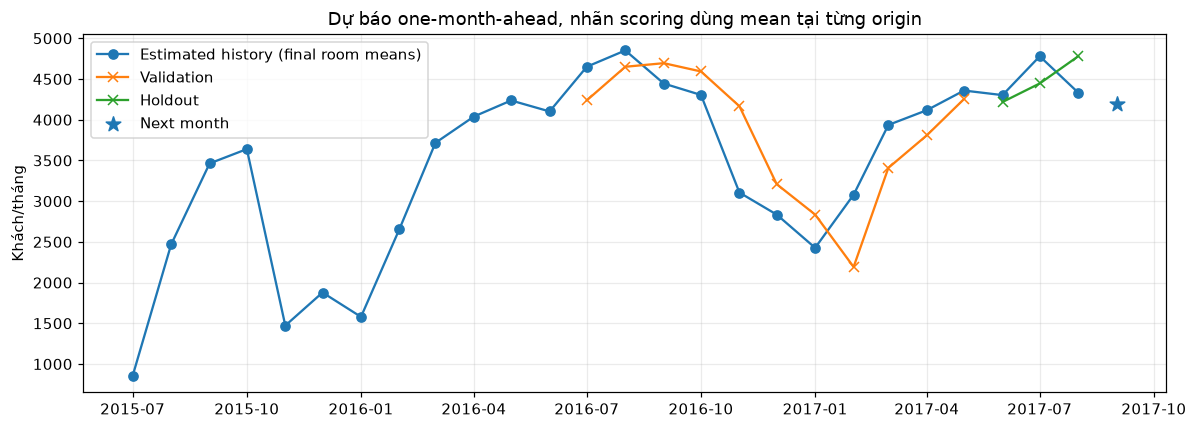

Chọn **M0_last_month_rate**, test MAE **288.16 khách/tháng**. Dự báo **2017-09: 4193.2 khách**, chưa có actual để kiểm chứng.

In [29]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index.to_timestamp(), monthly.target, marker='o', label='Estimated history (final room means)')
for title, frame in (('Validation', validation), ('Holdout', test)):
    p = frame[frame.model.eq(SELECTED)]
    ax.plot(pd.to_datetime(p.target_month), p.y_pred, marker='x', label=title)
ax.scatter([next_month.start_time], [next_prediction], marker='*', s=100, label='Next month')
ax.set(ylabel='Khách/tháng', title='Dự báo one-month-ahead, nhãn scoring dùng mean tại từng origin')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'monthly_forecast.png')
plt.show()
row = comparison[comparison.model.eq(SELECTED)].iloc[0]
Markdown(f"Chọn **{SELECTED}**, test MAE **{row.holdout_MAE:.2f} khách/tháng**. "
    f"Dự báo **{next_month}: {next_prediction:.1f} khách**, chưa có actual để kiểm chứng.")

## Lưu kết quả và kiểm tra khả năng chạy lại

Lưu bảng và manifest theo run riêng. Đối chiếu checksum nguồn và notebook cũ
sau thực nghiệm, các kết quả số ở trên được tính lại trong lần Run All này.

In [30]:
checks = {
    'inputs_unchanged': all(sha(SOURCE_DIR / name) == value for name, value in source_hashes.items()),
    'old_notebooks_unchanged': all(sha(ROOT / name) == value for name, value in old_hashes.items()),
    'selection_unchanged': sha(OUT / 'selection.json') == selection_hash,
    '26_complete_months': len(monthly) == 26 and bool(np.array_equal(monthly.calendar_days, monthly.index.days_in_month)),
    'room_source_unchanged': sha(room_path) == room_source['sha256'],
}
assert all(checks.values()), checks
save_json('verification.json', {'checks': checks, 'passed': True, 'fresh_execution': True,
                                'source_point_in_time_verified': False})
notebook = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
code_hash = hashlib.sha256(json.dumps([c['source'] for c in notebook['cells']
                          if c['cell_type'] == 'code'], ensure_ascii=False).encode()).hexdigest()
save_json('artifact_manifest.json', {'files': {p.name: sha(p) for p in OUT.iterdir() if p.is_file()},
                                      'notebook_code_sha256': code_hash})
pd.Series(checks, name='passed')

inputs_unchanged           True
old_notebooks_unchanged    True
selection_unchanged        True
26_complete_months         True
room_source_unchanged      True
Name: passed, dtype: bool

In [31]:
print('Hoàn tất:', OUT.relative_to(ROOT))

Hoàn tất: artifacts\forecasting\monthly_demand_forecast_report\20261110T051147_8eba5ce2
